# Evaluación Parcial N°2: Machine Learning
## Inteligencia Musical y Predicción de Popularidad de Canciones (Spotify Tracks)
|Campo|Detalle|
|---|---|
|Integrantes| Catalina Villegas y Javiera Fuenzalida|
|Sección| 002D|
|Asignatura| Machine Learning|
|Docente| Ignacio Meza|

Notebook de comprensión y preparación de datos (EDA). Genera `Spotify_Tracks_Dataset_Clean.csv`, insumo del notebook de modelado.


## **Analizando y tratando el DataSet**

### Librerias

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
from pathlib import Path


### Carga Principal

El notebook funciona en el repositorio local (`notebooks/`, datos en `../data`) y en Google Colab (CSV subido a la sesión). Las rutas se detectan automáticamente.


In [25]:
ARCHIVO_RAW = 'Spotify_Tracks_Dataset.csv'
ARCHIVO_CLEAN = 'Spotify_Tracks_Dataset_Clean.csv'

if Path('../data', ARCHIVO_RAW).exists():
    CARPETA_DATOS, RUTA_IMAGENES = Path('../data'), Path('../images')
elif Path('data', ARCHIVO_RAW).exists():
    CARPETA_DATOS, RUTA_IMAGENES = Path('data'), Path('images')
elif Path(ARCHIVO_RAW).exists():
    CARPETA_DATOS, RUTA_IMAGENES = Path('.'), Path('images')
else:
    raise FileNotFoundError(
        f'No se encontró {ARCHIVO_RAW}. En Colab, súbelo al panel de archivos (ícono de carpeta) y vuelve a ejecutar.')

RUTA_IMAGENES.mkdir(exist_ok=True)
RUTA_RAW = CARPETA_DATOS / ARCHIVO_RAW
RUTA_CLEAN = CARPETA_DATOS / ARCHIVO_CLEAN


In [26]:

df = pd.read_csv(RUTA_RAW)
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')
print('-' * 60)

print('\n1. PRIMERAS 5 FILAS (ejemplo completado):')
display(df.head())
print('-' * 60)
print(f"\n2. INFORMACIÓN:\n")
print(df.info())
print(f"\n3. ESTADÍSTICAS:\n{df.describe()}")

Dataset cargado: 114000 filas x 21 columnas
------------------------------------------------------------

1. PRIMERAS 5 FILAS (ejemplo completado):


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


------------------------------------------------------------

2. INFORMACIÓN:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  fl

In [27]:
df = df.drop('Unnamed: 0', axis=1)

print(f"Datos duplicados: {df.duplicated().sum()}")
print("track_id repetidos:", df["track_id"].duplicated().sum())    # 24.259
print('-'*60)

print(f"Datos faltantes: \n{df.isna().sum()}")
print('-'*60)

print(f"Datos fuera de rango:")
print(f"  - popularity: {((df['popularity'] < 0) | (df['popularity'] > 100)).sum()}")
print(f"  - duration_ms: {((df['duration_ms'] <= 0)).sum()}")
print(f"  - danceability: {((df['danceability'] < 0) | (df['danceability'] > 1)).sum()}")
print(f"  - energy: {((df['energy'] < 0) | (df['energy'] > 1)).sum()}")
print(f"  - key: {((df['key'] < -1) | (df['key'] > 11)).sum()}")
print(f"  - loudness: {((df['loudness'] < -60)).sum()}")
print(f"  - mode: {((df['mode'] != 0) & (df['mode'] != 1)).sum()}")
print(f"  - speechiness: {((df['speechiness'] < 0) | (df['speechiness'] > 1)).sum()}")
print(f"  - acousticness: {((df['acousticness'] < 0) | (df['acousticness'] > 1)).sum()}")
print(f"  - instrumentalness: {((df['instrumentalness'] < 0) | (df['instrumentalness'] > 1)).sum()}")
print(f"  - liveness: {((df['liveness'] < 0) | (df['liveness'] > 1)).sum()}")
print(f"  - valence: {((df['valence'] < 0) | (df['valence'] > 1)).sum()}")
print(f"  - tempo: {(df['tempo'] == 0).sum()}")
print(f"  - time_signature: {(df['time_signature'] == 0).sum()}")

Datos duplicados: 450
track_id repetidos: 24259
------------------------------------------------------------
Datos faltantes: 
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
------------------------------------------------------------
Datos fuera de rango:
  - popularity: 0
  - duration_ms: 1
  - danceability: 0
  - energy: 0
  - key: 0
  - loudness: 0
  - mode: 0
  - speechiness: 0
  - acousticness: 0
  - instrumentalness: 0
  - liveness: 0
  - valence: 0
  - tempo: 157
  - time_signature: 163


### Tratamiento de Datos

In [28]:
df_clean = df[df["popularity"] > 0].copy()
df_clean = df_clean.drop_duplicates()
print(f"Datos duplicados: {df_clean.duplicated().sum()}")

# Verificar cuántas filas quedaron y confirmar que el mínimo ya no sea 0
print(f"Filas restantes: {len(df_clean)}")
print(f"Popularidad mínima: {df_clean['popularity'].min()}")


Datos duplicados: 0
Filas restantes: 97706
Popularidad mínima: 1


In [29]:
print(f"duration_ms:    {((df_clean['duration_ms'] <= 0)).sum()}")
print(f"tempo:          {(df['tempo'] == 0).sum()} | {100*((df_clean['tempo'] == 0).sum())/len(df_clean):.3f}% ")
print(f"time_signature: {(df['time_signature'] == 0).sum()} | {100*((df_clean['time_signature'] == 0).sum())/len(df_clean):.3f}%")

duration_ms:    0
tempo:          157 | 0.157% 
time_signature: 163 | 0.163%


In [30]:
# Reemplaza valores <= 0 por NaN de forma segura
df_clean.loc[df_clean['tempo'] <= 0, 'tempo'] = np.nan
df_clean.loc[df_clean['time_signature'] <= 0, 'time_signature'] = np.nan

display(df[df['artists'].isna()])
display(df[df['album_name'].isna()])
display(df[df['track_name'].isna()])

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [31]:
#Eliminar unica fila con los datos faltantes
df_clean = df_clean.dropna(subset=["artists", "album_name", "track_name"])

#Rellenar datos faltantes restante
df_clean['tempo'] = df_clean['tempo'].fillna(df_clean['tempo'].median())
df_clean['time_signature'] = df_clean['time_signature'].fillna(df_clean['time_signature'].median())


print(f"Datos faltantes luego de rellenar: \n{df_clean.isna().sum()}")
print(df_clean.info())

Datos faltantes luego de rellenar: 
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 97706 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          97706 non-null  object 
 1   artists           97706 non-null  object 
 2   album_name        97706 non-null  object 
 3   track_name        97706 non-null  object 
 4   popularity        97706 non-null  int64  
 5   duration_ms       97706 non-null  int64  
 6   explicit          97706 n

In [32]:
# 2. Efecto Artista y Colaboraciones
df_clean["is_collab"] = df_clean["artists"].str.contains(";", na=False).astype(int)
df_clean["artist_song_count"] = df_clean.groupby("artists")["track_id"].transform("count")

# 3. Interacciones comerciales
df_clean["party_index"] = df_clean["danceability"] * df_clean["energy"]
df_clean["dist_to_3min"] = abs(df_clean["duration_ms"] - 180000)
df_clean['acoustic_energy'] = df_clean['energy'] * (1 - df_clean['acousticness'])
# 4. Comparación contra su propio género
for col in ["danceability", "energy", "loudness", "valence"]:
  genre_mean = df_clean.groupby("track_genre")[col].transform("mean")
  df_clean[f"{col}_diff_genre"] = df_clean[col] - genre_mean


In [33]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 97706 entries, 0 to 113999
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   track_id                 97706 non-null  object 
 1   artists                  97706 non-null  object 
 2   album_name               97706 non-null  object 
 3   track_name               97706 non-null  object 
 4   popularity               97706 non-null  int64  
 5   duration_ms              97706 non-null  int64  
 6   explicit                 97706 non-null  bool   
 7   danceability             97706 non-null  float64
 8   energy                   97706 non-null  float64
 9   key                      97706 non-null  int64  
 10  loudness                 97706 non-null  float64
 11  mode                     97706 non-null  int64  
 12  speechiness              97706 non-null  float64
 13  acousticness             97706 non-null  float64
 14  instrumentalness         9

In [34]:
# Popularidad promedio de cada género, de mayor a menor
popularidad_por_genero = df_clean.groupby("track_genre")["popularity"].mean().sort_values(ascending=False)

# Nos quedamos con los 25 más populares y los 25 menos populares
top_25_generos = popularidad_por_genero.head(25).index
bottom_25_generos = popularidad_por_genero.tail(25).index
generos_elegidos = top_25_generos.union(bottom_25_generos)

df_filtrado = df_clean[df_clean["track_genre"].isin(generos_elegidos)].copy()
print(df_filtrado.shape, df_filtrado["track_genre"].nunique())

(42409, 29) 50


In [35]:
df_filtrado.to_csv(RUTA_CLEAN, index = False)

### **Análisis Exploratorio de Datos (EDA) y KPIs**

Tasa de Hits Potenciales (Hit Ratio Global): 7.53%

Hit Ratio por Género:
          track_genre  total_canciones  total_hits  hit_ratio_pct
40                pop              815         317      38.895706
16            electro              622         241      38.745981
25              house              596         221      37.080537
15                edm              634         181      28.548896
47               soul              389         107      27.506427
36              metal              793         217      27.364439
28              indie              712         185      25.983146
1            alt-rock              650         165      25.384615
29          indie-pop              741         177      23.886640
33              k-pop              960         225      23.437500
23            hip-hop              708         134      18.926554
21          hard-rock              858         147      17.132867
35              latin              405          61      15.061728
46

/tmp/ipykernel_684/1111910238.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_filtrado, x='is_hit', ax=axes[1], palette='viridis')


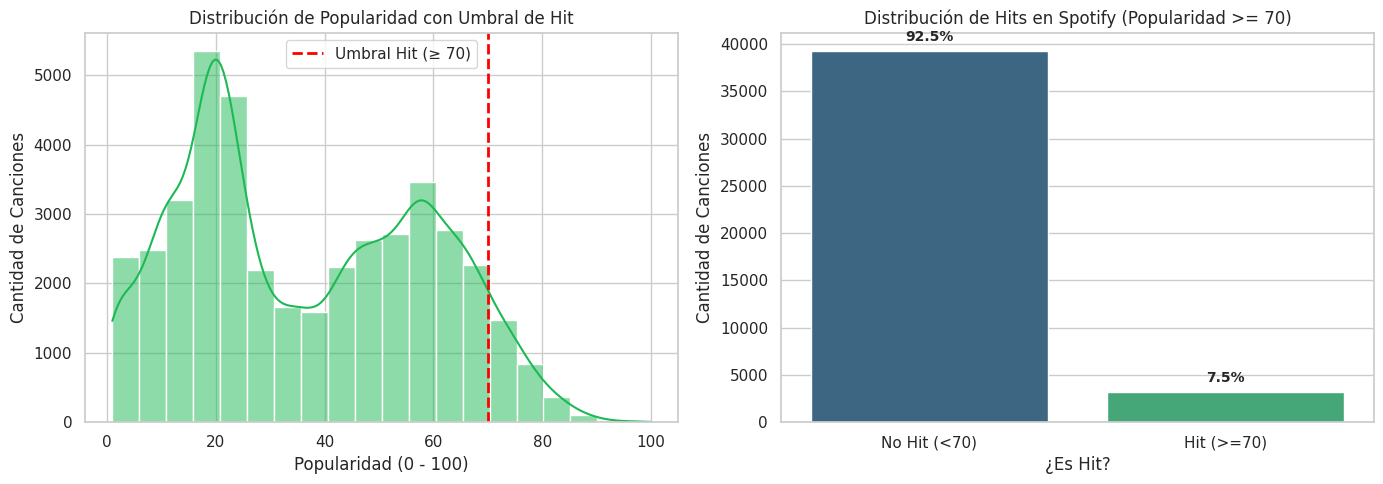

In [36]:
# KPI 1: Graficos Hits

UMBRAL_HIT = 70
sns.set_theme(style="whitegrid")

df_filtrado['is_hit'] = (df_filtrado['popularity'] >= UMBRAL_HIT).astype(int)

hit_ratio_global = df_filtrado['is_hit'].mean() * 100
print(f"Tasa de Hits Potenciales (Hit Ratio Global): {hit_ratio_global:.2f}%\n")

hit_ratio_por_genero = df_filtrado.groupby('track_genre')['is_hit'].agg(
    total_canciones='count',
    total_hits='sum',
    hit_ratio_pct=lambda x: x.mean() * 100
).reset_index().sort_values(by='hit_ratio_pct', ascending=False)

print("Hit Ratio por Género:")
print(hit_ratio_por_genero)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Histograma de Popularidad
sns.histplot(data=df_filtrado, x='popularity', kde=True, ax=axes[0], color='#1DB954', bins=20)
axes[0].axvline(UMBRAL_HIT, color='red', linestyle='--', linewidth=2, label=f'Umbral Hit (≥ {UMBRAL_HIT})')
axes[0].set_title('Distribución de Popularidad con Umbral de Hit')
axes[0].set_xlabel('Popularidad (0 - 100)')
axes[0].set_ylabel('Cantidad de Canciones')
axes[0].legend()

# Gráfico 2: Contador de Hits vs No Hits
sns.countplot(data=df_filtrado, x='is_hit', ax=axes[1], palette='viridis')
axes[1].set_title(f'Distribución de Hits en Spotify (Popularidad >= {UMBRAL_HIT})')
axes[1].set_xlabel('¿Es Hit?')
axes[1].set_ylabel('Cantidad de Canciones')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Hit (<70)', 'Hit (>=70)'])

total = len(df_filtrado)
for p in axes[1].patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'

    x_pos = p.get_x() + p.get_width() / 2
    y_pos = p.get_height()

    axes[1].annotate(percentage, (x_pos, y_pos),
                     ha='center', va='bottom',
                     fontsize=10, fontweight='bold',
                     xytext=(0, 5), textcoords='offset points')

# Ajustar diseño y mostrar
plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'graficos_HIT.png')
plt.show()


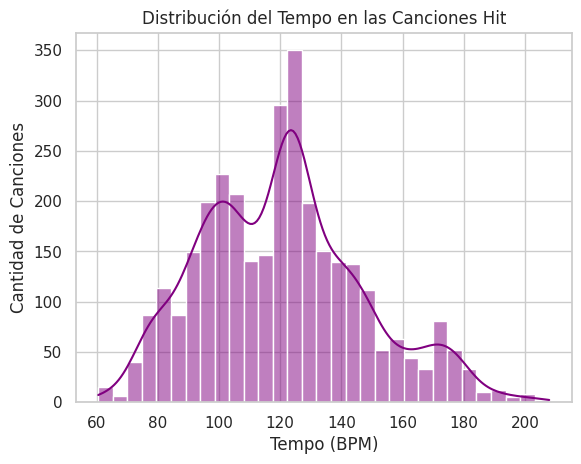

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtramos el DataFrame para quedarnos SOLO con los que son Hit
df_hits = df_filtrado[df_filtrado['is_hit'] == 1]

# Creamos el gráfico (ejemplo con la variable 'tempo')
sns.histplot(data=df_hits, x='tempo', kde=True, color='purple')
plt.title('Distribución del Tempo en las Canciones Hit')
plt.xlabel('Tempo (BPM)')
plt.ylabel('Cantidad de Canciones')

plt.savefig(RUTA_IMAGENES / 'histograma_tempo_hits.png')
plt.show()


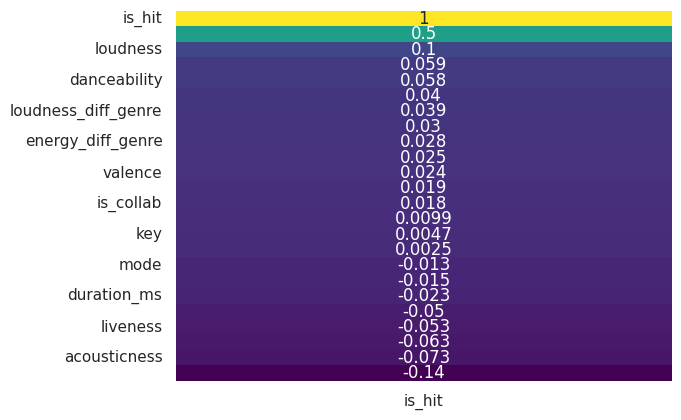

In [38]:
# Correlación de todas las variables numéricas con respecto a si es hit o no
correlacion = df_filtrado.select_dtypes(include=['number']).corr()
sns.heatmap(correlacion[['is_hit']].sort_values(by='is_hit', ascending=False),
            annot=True, cmap='viridis', cbar=False)
plt.savefig(RUTA_IMAGENES / 'heatmap_correlacion_is_hit.png', bbox_inches='tight')
plt.show()


/tmp/ipykernel_684/1318393334.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top, x='artists', y='popularity', palette='viridis')


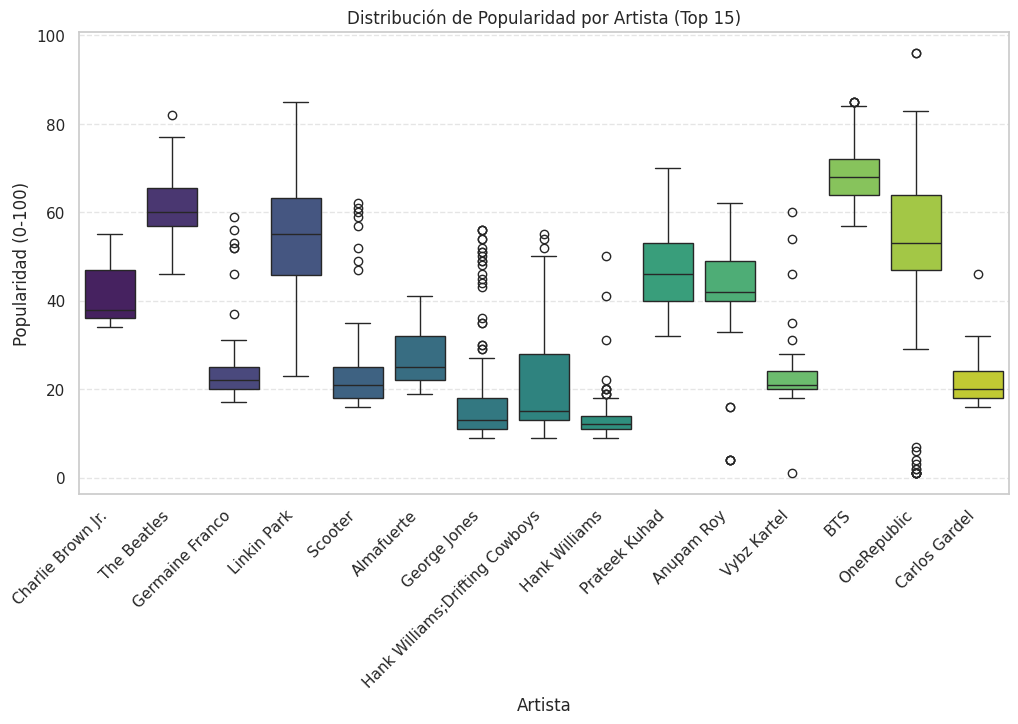

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Elegimos los 15 artistas con más canciones en el dataset para que sea representativo
top_artistas = df_filtrado['artists'].value_counts().head(15).index
df_top = df_filtrado[df_filtrado['artists'].isin(top_artistas)]

# 2. Graficamos
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='artists', y='popularity', palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Distribución de Popularidad por Artista (Top 15)')
plt.xlabel('Artista')
plt.ylabel('Popularidad (0-100)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.savefig(RUTA_IMAGENES / 'boxplot_artistas_popularidad.png')
plt.show()

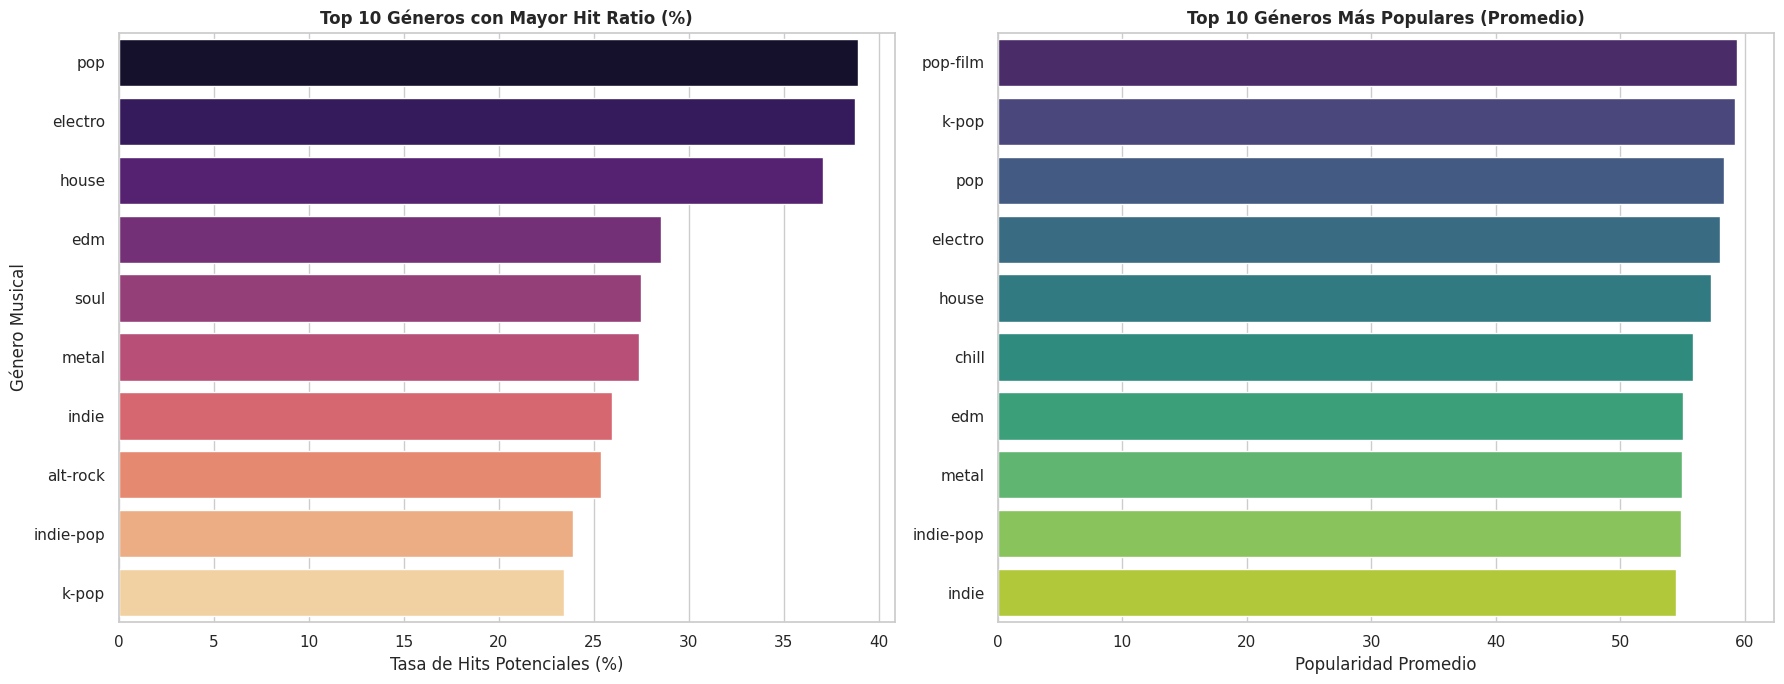

In [40]:
# KPI 2: Top 10 Géneros por Popularidad Promedio Y Géneros con mayor Porcentaje Hit

import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico Izquierdo: Top 10 Géneros por Hit Ratio
hit_ratio_por_genero = df_filtrado.groupby('track_genre')['is_hit'].agg(
    total_canciones='count',
    total_hits='sum',
    hit_ratio_pct=lambda x: (x.mean() * 100)
).reset_index().sort_values(by='hit_ratio_pct', ascending=False).head(10)

# Gráfico Derecho: Top 10 Géneros por Popularidad Promedio
genre_popularity = df_filtrado.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))  # Una fila, dos columnas

# Hit Ratio por Género
sns.barplot(
    data=hit_ratio_por_genero,
    x='hit_ratio_pct',
    y='track_genre',
    hue='track_genre',
    palette='magma',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Top 10 Géneros con Mayor Hit Ratio (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tasa de Hits Potenciales (%)')
axes[0].set_ylabel('Género Musical')

# Popularidad Promedio por Género
sns.barplot(
    x=genre_popularity.values,
    y=genre_popularity.index,
    hue=genre_popularity.index,
    palette='viridis',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Top 10 Géneros Más Populares (Promedio)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Popularidad Promedio')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'graficos_generos.png')
plt.show()


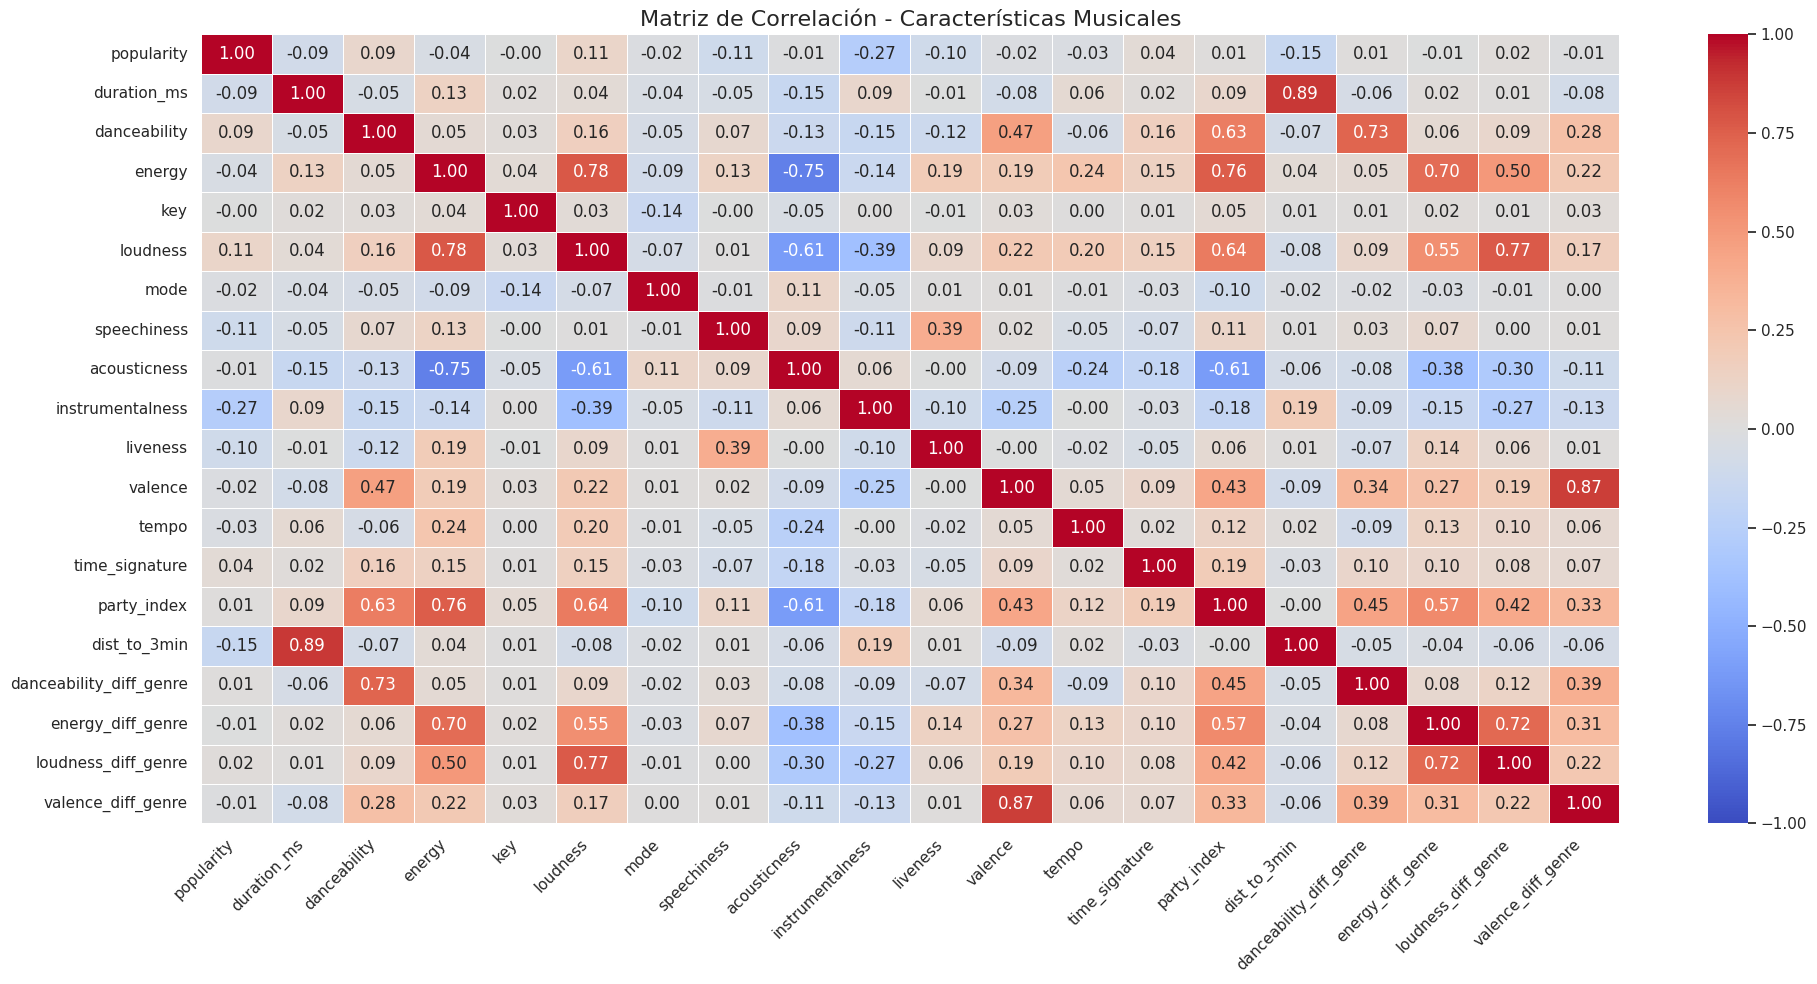

In [41]:
# KPI 3: Mapa de Calor del Índice de Afinidad Sonora

columnas_interes = [
    'popularity', 'duration_ms', 'danceability', 'energy',
    'key', 'loudness', 'mode', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
    'party_index', 'dist_to_3min', 'danceability_diff_genre', 'energy_diff_genre',
    'loudness_diff_genre', 'valence_diff_genre'
]

df_numerico = df_filtrado[columnas_interes]

matriz_corr = df_numerico.corr()

plt.figure(figsize=(20, 10))
sns.heatmap(
    matriz_corr,
    annot=True,          # Muestra el valor numérico en cada celda
    cmap='coolwarm',     # Escala de azul (negativo) a rojo (positivo)
    fmt='.2f',           # Muestra solo 2 decimales
    linewidths=0.5,      # Añade una línea de separación entre celdas
    vmin=-1, vmax=1      # Normaliza la escala de color entre -1 y 1
)

plt.title('Matriz de Correlación - Características Musicales', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'mapa_calor.png')
plt.show()

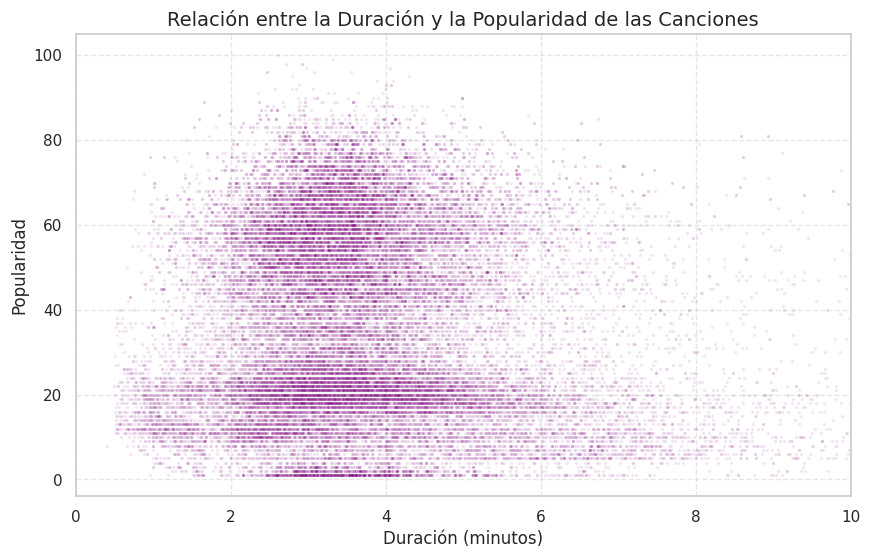

In [42]:
# KPI 4: Duración Óptima vs Popularidad

# Convertir la duración a minutos para que el gráfico sea más legible
df_filtrado['duration_min'] = df_filtrado['duration_ms'] / 60000


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_filtrado,
    x='duration_min',
    y='popularity',
    alpha=0.1,
    s=5,
    color='purple'
)

plt.title('Relación entre la Duración y la Popularidad de las Canciones', fontsize=14)
plt.xlabel('Duración (minutos)', fontsize=12)
plt.ylabel('Popularidad', fontsize=12)
plt.xlim(0, 10)

plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig(RUTA_IMAGENES / 'grafico_relacion.png')
plt.show()


### **Optimizaciones del Dataset para Modelamiento Predictivo**
Para garantizar un rendimiento óptimo de los modelos de Machine Learning, aplicaremos técnicas avanzadas de preparación:
* **Tratamiento de Outliers (Winsorización/Acotado):** Limitaremos la duración máxima para evitar valores extremos ruidosos.
* **Transformaciones para Distribuciones Sesgadas:** Aplicaremos transformaciones logarítmicas en variables acústicas altamente asimétricas.
* **Codificación y Escalado de Variables:** Convertiremos variables binarias faltantes a formato numérico puro ($0/1$).

In [43]:
import numpy as np
import pandas as pd

# 1. Copia de seguridad del DataFrame filtrado
df_ml = df_filtrado.copy()

# 2. Tratamiento de Outliers en la Duración (Acotar al percentil 99)
limite_superior_duracion = df_ml['duration_ms'].quantile(0.99)
df_ml['duration_ms'] = df_ml['duration_ms'].clip(upper=limite_superior_duracion)

# 3. Conversión de Variables Booleanas a Enteras (0 o 1)
df_ml['explicit'] = df_ml['explicit'].astype(int)

# 4. Transformación Logarítmica para reducir asimetría extrema
# Atributos como speechiness e liveness suelen tener una distribución log-normal sesgada
for col in ['speechiness', 'liveness', 'instrumentalness']:
    df_ml[f'{col}_log'] = np.log1p(df_ml[col])

# 5. Eliminar columnas que actúan como identificadores o redundantes para evitar sobreajuste directo
# 'track_id', 'track_name', 'album_name', 'artists' son metadatos de texto libre de alta cardinalidad
columnas_a_excluir = ['track_name', 'album_name']
df_ml_final = df_ml.drop(columns=[col for col in columnas_a_excluir if col in df_ml.columns])

print(f"Dimensiones finales para entrenamiento: {df_ml_final.shape}")
display(df_ml_final.head())

df_ml_final['track_genre'].unique()

Dimensiones finales para entrenamiento: (42409, 32)


,track_id,artists,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,...,acoustic_energy,danceability_diff_genre,energy_diff_genre,loudness_diff_genre,valence_diff_genre,is_hit,duration_min,speechiness_log,liveness_log,instrumentalness_log
1000,4pR4oQJULf7FDB54TleMyH,Limoblaze;Lecrae;Happi,64,168000.0,0,0.443,0.778,0,-7.564,0,...,0.590502,-0.226192,0.075855,0.196109,-0.068724,0,2.800000,0.235862,0.194744,0.000000
1001,4Ds4bq6aqOSAp1T7DikOi4,Criolo,44,318360.0,0,0.580,0.800,6,-7.528,1,...,0.575200,-0.089192,0.097855,0.232109,-0.213724,0,5.306000,0.296394,0.068406,0.000000
1002,7nYbKsvhM88mHCmFsAIQVp,Criolo,42,171989.0,0,0.805,0.746,1,-5.211,0,...,0.568452,0.135808,0.043855,2.549109,0.020276,0,2.866483,0.169743,0.194744,0.000000
1003,7gVNP7rI9UBZndge0ulKfL,Criolo,46,205440.0,0,0.582,0.660,7,-4.988,0,...,0.396660,-0.087192,-0.042145,2.772109,-0.212724,0,3.424000,0.052972,0.119559,0.000000
1004,1hLvWelTny8vttEEZIXVjw,Criolo,44,220800.0,0,0.776,0.314,2,-9.513,1,...,0.037366,0.106808,-0.388145,-1.752891,-0.220724,0,3.680000,0.033435,0.130151,0.000723


array(['afrobeat', 'alt-rock', 'anime', 'black-metal', 'bluegrass',
       'breakbeat', 'british', 'chicago-house', 'chill', 'classical',
       'comedy', 'deep-house', 'detroit-techno', 'disney',
       'drum-and-bass', 'edm', 'electro', 'emo', 'grindcore', 'grunge',
       'happy', 'hard-rock', 'heavy-metal', 'hip-hop', 'honky-tonk',
       'house', 'idm', 'indian', 'indie-pop', 'indie', 'iranian',
       'j-dance', 'j-idol', 'k-pop', 'kids', 'latin', 'metal', 'opera',
       'party', 'piano', 'pop-film', 'pop', 'progressive-house',
       'romance', 'sad', 'singer-songwriter', 'songwriter', 'soul',
       'study', 'tango'], dtype=object)

### **Exportación del Dataset Depurado para Modelos**
Guardamos la versión optimizada en `Spotify_Tracks_Dataset_Clean.csv` lista para ser cargada en la fase de modelamiento.

In [44]:
# Sobrescribimos el archivo limpio con la estructura optimizada para Machine Learning
df_ml_final.to_csv(RUTA_CLEAN, index=False)
print(f"Dataset final optimizado exportado exitosamente en: {RUTA_CLEAN}")

Dataset final optimizado exportado exitosamente en: Spotify_Tracks_Dataset_Clean.csv
